# QPINN — training, evaluation, and plotting
End-to-end walkthrough using the new pipeline (`train.py`, `eval.py`, `plotter.py`).

## 0 - Setup

In [1]:
import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models import MerlinHeatQPINN
from src.pde import HeatEquation          # swap for BurgersPDE / WavePDE as needed
from src.loss import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import plot_training_history, plot_solution_comparison

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: cpu  |  dtype: torch.float32


## 1 - Build QPINN model and PDE

In [14]:
# Model
model = MerlinHeatQPINN()
model = model.to(device)

In [13]:
used_pde = HeatEquation(freq=0.5)

## 2 - Train model

In [15]:
history = train(model = model, pde = used_pde, epochs=600)

Parameters — total: 250  trainable: 250

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 5.3399e+00 | PDE: 1.35e-05 | Cons: 2.05e-02 | IC: 5.34e-01 | BC: 2.57e-04 | Time: 0.0s
Epoch    50/600 | Loss: 1.1525e+00 | PDE: 6.44e-02 | Cons: 1.16e-01 | IC: 7.82e-02 | BC: 2.95e-01 | Time: 1.4s
Epoch   100/600 | Loss: 2.8421e-01 | PDE: 6.45e-02 | Cons: 1.47e+00 | IC: 3.80e-03 | BC: 3.43e-02 | Time: 2.8s
Epoch   150/600 | Loss: 2.3645e-01 | PDE: 4.52e-02 | Cons: 1.36e+00 | IC: 1.96e-03 | BC: 3.55e-02 | Time: 4.2s
Epoch   200/600 | Loss: 7.5600e-02 | PDE: 1.36e-02 | Cons: 3.34e-01 | IC: 1.03e-03 | BC: 1.83e-02 | Time: 5.6s
Epoch   250/600 | Loss: 1.9447e-02 | PDE: 5.88e-03 | Cons: 6.40e-02 | IC: 5.37e-04 | BC: 1.80e-03 | Time: 7.0s
Epoch   300/600 | Loss: 7.7410e-03 | PDE: 2.19e-03 | Cons: 4.67e-02 | IC: 6.43e-05 | BC: 2.42e-04 | Time: 8.5s
Epoch   350/600 | Loss: 6.0667e-03 | PDE: 1.76e-03 | Cons: 3.14e-02 | IC: 1.00e-04 | BC: 1.74e-04 | Time: 9.8s
Epoch   400/600 |

## 3 - Plot training history

Saved: ../figures/demo/history.png


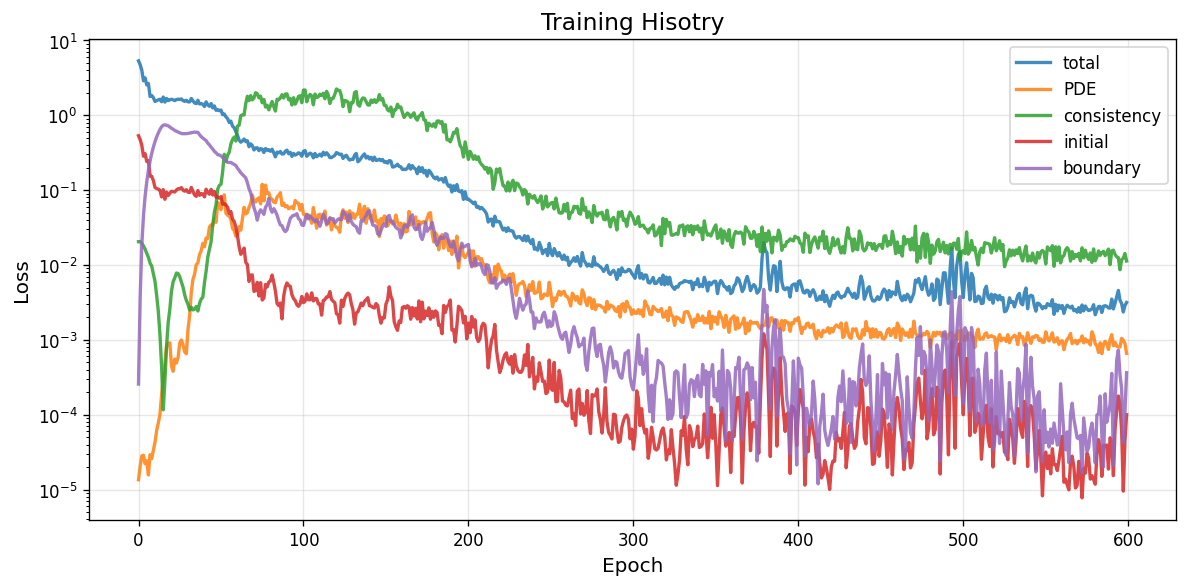

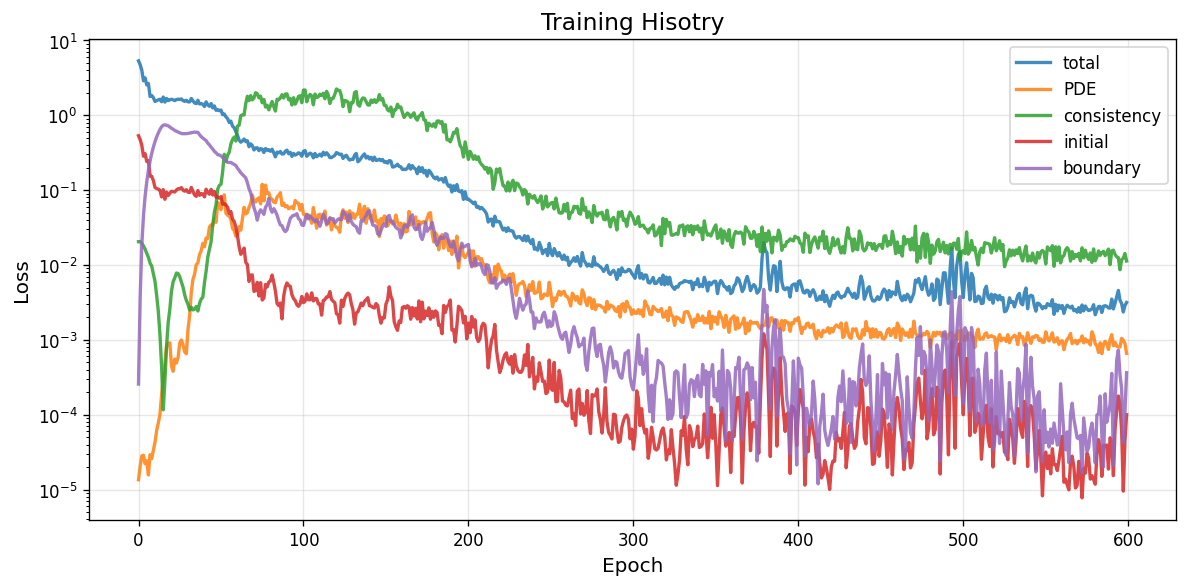

In [16]:
plot_training_history(
    history,
    save_path ='../figures/demo/history.png',  # set to None to skip saving
    show      = True,
)

## 7 - Evaluate model over grid

In [17]:
metrics, U_pred, U_true, x_grid, t_grid = evaluate(
    model  = model,
    pde    = used_pde
)
print(metrics)

Evaluating on 60×60 grid …
  Relative L2 : 1.9916e-02
  MAE         : 1.0264e-02
  Max abs err : 2.6831e-02
  RMSE        : 1.2409e-02
{'rel_l2': 0.019915953278541565, 'mae': 0.010264312848448753, 'max_abs_error': 0.02683146297931671, 'rmse': 0.012408827431499958}


## 8 - Plot solution comparison

Saved: ../figures/demo/solution_quant.png


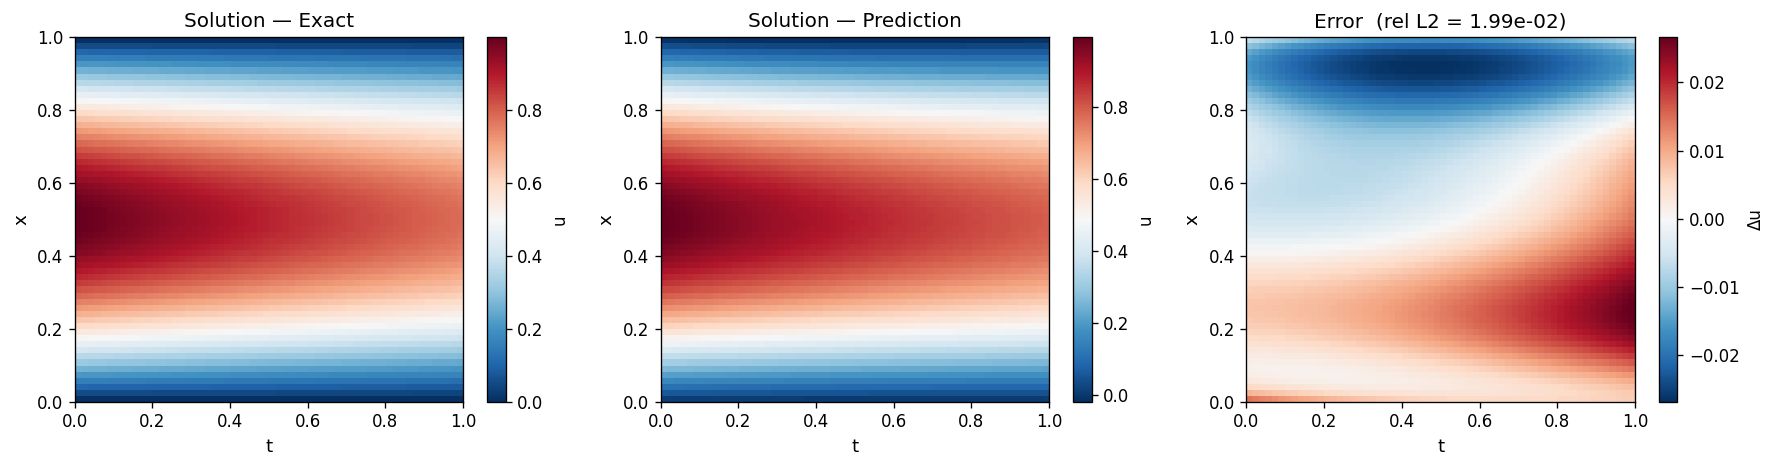

Relative L2 error: 1.9916e-02


In [18]:
fig, rel_l2 = plot_solution_comparison(
    U_pred    = U_pred,
    U_true    = U_true,
    x_grid    = x_grid,
    t_grid    = t_grid,
    save_path ='../figures/demo/solution_quant.png',
    show      = True,
)
print(f'Relative L2 error: {rel_l2:.4e}')

## 9 - Repeat process for Classial PINN to compare result

Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 1.6017e+00 | PDE: 3.86e-04 | Cons: 4.71e-02 | IC: 1.08e-01 | BC: 5.19e-01 | Time: 0.0s
Epoch    50/600 | Loss: 1.4189e+00 | PDE: 1.20e-01 | Cons: 2.92e-04 | IC: 1.10e-01 | BC: 2.02e-01 | Time: 0.1s
Epoch   100/600 | Loss: 6.1648e-01 | PDE: 7.28e-02 | Cons: 4.01e-01 | IC: 3.59e-02 | BC: 1.45e-01 | Time: 0.1s
Epoch   150/600 | Loss: 4.1644e-02 | PDE: 5.17e-03 | Cons: 9.54e-02 | IC: 1.61e-03 | BC: 1.08e-02 | Time: 0.2s
Epoch   200/600 | Loss: 1.2326e-02 | PDE: 3.30e-03 | Cons: 4.99e-02 | IC: 2.41e-04 | BC: 1.64e-03 | Time: 0.3s
Epoch   250/600 | Loss: 6.0386e-03 | PDE: 2.00e-03 | Cons: 2.53e-02 | IC: 1.12e-04 | BC: 3.80e-04 | Time: 0.3s
Epoch   300/600 | Loss: 5.3590e-03 | PDE: 1.18e-03 | Cons: 2.78e-02 | IC: 1.09e-04 | BC: 3.07e-04 | Time: 0.4s
Epoch   350/600 | Loss: 5.3377e-03 | PDE: 7.49e-04 | Cons: 2.43e-02 | IC: 1.70e-04 | BC: 4.58e-04 | Time: 0.4s
Epoch   400/600 |

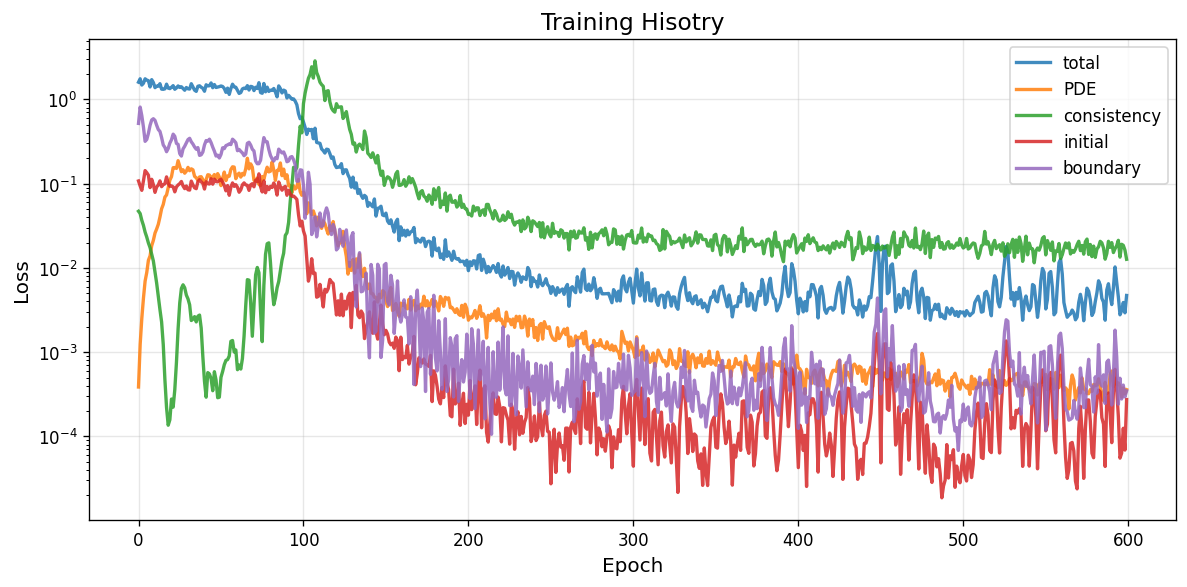

Saved: ../figures/demo/solution_class.png


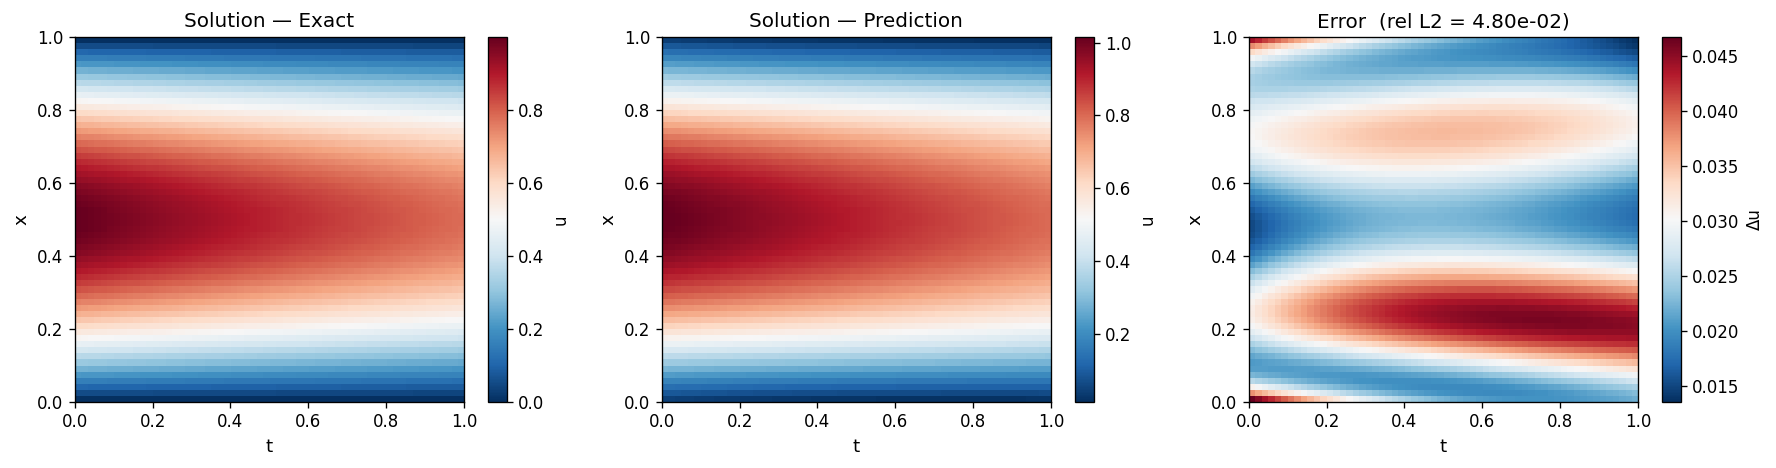

Relative L2 error: 4.7954e-02


In [19]:
from src.models import ClassicalHeatQPINN


classical_model = ClassicalHeatQPINN()
classical_model = classical_model.to(device)


history = train(model = classical_model, pde = used_pde, loss_fn=total_loss, epochs=600)

metrics, U_pred, U_true, x_grid, t_grid = evaluate(
    model  = classical_model,
    pde    = used_pde,
)

plot_training_history(
    history,
    save_path ='../figures/demo/history.png',  # set to None to skip saving
    show      = True,
)

fig, rel_l2 = plot_solution_comparison(
    U_pred    = U_pred,
    U_true    = U_true,
    x_grid    = x_grid,
    t_grid    = t_grid,
    save_path ='../figures/demo/solution_class.png',
    show      = True,
)
print(f'Relative L2 error: {rel_l2:.4e}')